# HoloGuide: AI sees, rules decide, people oversee

HoloGuide checks a virtual four-step assembly (**base plate → gasket → cover → bolts**) and catches three mistakes:
a **missing part**, the **wrong part** (a green decoy cover) and parts in the **wrong order**. Everything runs
offline on one laptop.

1. A PyBullet scene renders the assembly from a fixed overhead camera.
2. An **inspector** sees only the image and reports an `Observation`: parts seen, confidence, one-sentence reason.
   It is evidence, not a decision.
3. Deterministic **rules** turn the Observation into a `Decision`: pass, block, needs review or hold.
4. The **workflow** advances only on a pass or a logged operator override with a typed reason. Every event goes
   to an audit log.

This notebook runs each piece, then the edge cases, then a small evaluation. It never downloads a model: Gemma
is used only if a local Ollama already serves `gemma3:4b`; otherwise the OpenCV inspector is used.

## 0. Setup

In [1]:
import os, sys, json, urllib.request
from datetime import datetime
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "config" / "assembly.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import pandas as pd
from src.config import load_config

config = load_config()
RUN_DIR = ROOT / "outputs" / "notebook" / datetime.now().strftime("%Y%m%d-%H%M%S")
RUN_DIR.mkdir(parents=True, exist_ok=False)
print(config.name, "-", len(config.steps), "steps; confidence threshold", config.confidence_threshold,
      "; AI timeout", config.ai_timeout_s, "s")
pd.DataFrame([{"step": s.id, "name": s.name, "adds": ", ".join(s.adds_parts)} for s in config.steps])

Sealed Cover Assembly - 4 steps; confidence threshold 0.7 ; AI timeout 20.0 s


,step,name,adds
0,1,Place base plate,base_plate
1,2,Insert gasket,gasket
2,3,Attach cover,cover
3,4,Install bolts,bolts


## 1. Choose an inspector

All inspectors share one contract, `inspect(image_path, step) -> Observation`. They never raise and never see the
simulator's ground truth.

| Inspector | What it does |
|---|---|
| `cv` | OpenCV colour masks + shape checks (no GPU, ~15 ms) |
| `gemma` | Gemma 3 4B through local Ollama, wrapped in the AI timeout |
| `hybrid` | OpenCV decides; Gemma only settles parts OpenCV is unsure about (the demo default) |

In [2]:
from src.vision import factories

def ollama_has_gemma(host="http://localhost:11434"):
    try:
        with urllib.request.urlopen(f"{host}/api/tags", timeout=1) as response:   # local only
            return any(m["name"].startswith("gemma3:4b") for m in json.load(response)["models"])
    except Exception:
        return False

INSPECTOR = os.environ.get("HOLOGUIDE_NOTEBOOK_INSPECTOR") or ("hybrid" if ollama_has_gemma() else "cv")
inspector = {"cv": factories.cv, "hybrid": factories.hybrid, "gemma": factories.gemma}[INSPECTOR](config)
print("Using", INSPECTOR, "->", type(inspector).__name__)

Using hybrid -> HybridInspector


## 2. Inspect one image by hand

Render the *missing gasket* mistake (the cover placed straight on the base plate) and check it as step 3.

In [3]:
from src.simulation.assembly_env import AssemblyEnv
from src.control.rules import RuleContext, evaluate

def render(parts, name):
    with AssemblyEnv(config, seed=0) as env:
        for part in parts:
            env.place_part(part)
        return env.render_to_file(str(RUN_DIR / name))

frame = render(["base_plate", "cover"], "missing_gasket.png")       # the gasket is missing
step = config.step(3)
observation = inspector.inspect(frame, step)                          # only the image path and the step
decision = evaluate(observation, step, config.confidence_threshold,
                    context=RuleContext.from_config(config, step))
print("Observation:", observation.model_dump_json(indent=2))
print("Decision:", decision.status.value, "-", decision.message, f"(decided by {decision.decided_by.value})")

Observation: {
  "parts_detected": [
    "base_plate",
    "cover"
  ],
  "missing_parts": [
    "gasket"
  ],
  "wrong_parts": [],
  "confidence": 0.95,
  "rationale": "OpenCV: saw Base plate, Cover. Bolts: 0 found."
}
Decision: block - Missing required part: Gasket. Add it and inspect Attach cover again. (decided by rule)


pybullet build time: Jan 29 2025 23:16:28


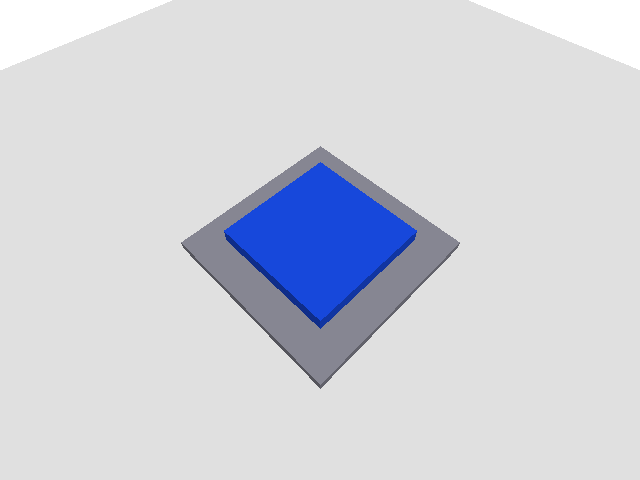

In [4]:
try:
    from IPython.display import display
    from PIL import Image
    display(Image.open(frame))
except ImportError:
    print("Image saved at", frame)

## 3. Run a full scenario through the workflow

`ScenarioRunner` plays scripted operator actions: the mistake is injected, the step is **blocked**, the operator
fixes it, the step is re-inspected and the workflow continues to **Complete**.

In [5]:
from src.control.audit_log import AuditLog
from src.control.workflow import Workflow
from src.simulation.runner import ScenarioRunner

SCENARIO = "missing_gasket"     # correct | missing_gasket | wrong_cover | wrong_order
audit = AuditLog(RUN_DIR / "audit.jsonl")
with AssemblyEnv(config, seed=0) as env:
    workflow = Workflow(config, inspector, audit)
    result = ScenarioRunner(SCENARIO, env, workflow, RUN_DIR / "frames").run()
print(result)
assert result.completed, result.error

RunResult(scenario='missing_gasket', completed=True, fault_status='block', recovered=True, guard_blocked=False, recovery_s=0.07567002900032094, decisions=['pass', 'block', 'pass', 'pass', 'pass'], error=None)


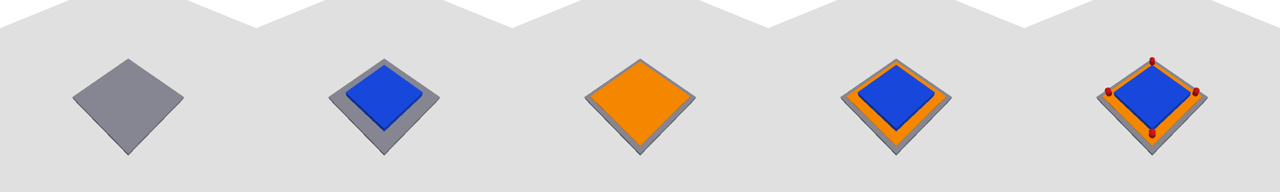

,frame,decision
0,001.png,pass
1,002.png,block
2,003.png,pass
3,004.png,pass
4,005.png,pass


In [6]:
frames = sorted((RUN_DIR / "frames").glob("*.png"))
try:
    from IPython.display import display
    from PIL import Image
    thumbs = [Image.open(f).resize((256, 192)) for f in frames]
    strip = Image.new("RGB", (256 * len(thumbs), 192), "white")
    for i, thumb in enumerate(thumbs):
        strip.paste(thumb, (256 * i, 0))
    display(strip)
except ImportError:
    pass
pd.DataFrame({"frame": [f.name for f in frames], "decision": result.decisions})

## 4. The audit log

Every action, inspection, decision and correction is one JSON line.

In [7]:
def audit_table(log):
    return pd.DataFrame([{
        "event": e["event_type"],
        "step": (e.get("current_step") or {}).get("id"),
        "next state": e.get("next_state"),
        "decision": (e.get("decision") or {}).get("status"),
        "detail": (e.get("decision") or {}).get("message") or e.get("reason") or e.get("part") or "",
    } for e in log.read_all()])

audit_table(audit)

,event,step,next state,decision,detail
0,scenario_started,NaN,None,None,
1,action_accepted,1.0,waiting,None,Base plate is allowed for Place base plate.
2,inspection_requested,1.0,inspecting,None,
3,inspection_passed,1.0,step_complete,pass,Step 1 verified: Place base plate. Continue to...
4,step_advanced,1.0,step_complete,pass,Step 1 verified: Place base plate. Continue to...
5,simulation_fault_injected,NaN,None,None,cover
6,inspection_requested,2.0,inspecting,None,
7,inspection_blocked,2.0,blocked,block,Incorrect assembly order: Cover belongs to a l...
8,scenario_correction,NaN,None,None,cover
9,scenario_correction_started,NaN,None,None,


## 5. Edge cases: unsure AI, slow AI and the operator

* An **unsure** observation (confidence below 0.70) goes to **Needs Review**; an operator approves it with a typed reason.
* An inspection that exceeds the **timeout** returns a safe zero-confidence observation and the workflow goes to
  **Hold**; an operator clears the hold, which does *not* approve the step.

`MockInspector` and `SlowInspector` are test doubles, used here only to force these paths.

In [8]:
from src.vision.inspector import MockInspector, SlowInspector, TimeoutInspector

edge_audit = AuditLog(RUN_DIR / "edge_cases.jsonl")
base_frame = render(["base_plate"], "base_plate.png")

unsure = Workflow(config, MockInspector(config, mode="uncertain"), edge_audit)
unsure.check_action("base_plate")
print("unsure AI ->", unsure.request_inspection(base_frame).status.value, "| state:", unsure.state.value)
approved = unsure.operator_override(True, "Visually confirmed the base plate is seated.", "operator-1")
print("override  ->", approved.status.value, "decided by", approved.decided_by.value, "| step now", unsure.current_step_id)

slow = TimeoutInspector(SlowInspector(MockInspector(config), delay_s=1.0), timeout_s=0.2)
held = Workflow(config, slow, edge_audit)
held.check_action("base_plate")
print("slow AI   ->", held.request_inspection(base_frame).status.value, "| state:", held.state.value)
held.clear_hold("operator-1", "Inspector restarted.")
print("hold cleared -> state:", held.state.value, "| step still", held.current_step_id)
audit_table(edge_audit)

unsure AI -> needs_review | state: needs_review
override  -> pass decided by operator | step now 2


slow AI   -> hold | state: hold
hold cleared -> state: waiting | step still 1


,event,step,next state,decision,detail
0,action_accepted,1,waiting,None,Base plate is allowed for Place base plate.
1,inspection_requested,1,inspecting,None,
2,inspection_needs_review,1,needs_review,needs_review,Inspection confidence 40% is below the require...
3,operator_override,1,None,pass,Operator operator-1 approved step 1: Visually ...
4,action_accepted,1,waiting,None,Base plate is allowed for Place base plate.
5,inspection_requested,1,inspecting,None,
6,inspection_hold,1,hold,hold,Inspection failed or returned no reliable evid...
7,hold_cleared,1,waiting,None,Inspector restarted.


## 6. A small evaluation you can rerun here

Generate a fresh labelled mini-dataset (labels stay in a separate CSV that the inspector never sees) and score the
chosen inspector with the project's evaluation runner. The full 200-image results are in section 7.

In [9]:
from src.simulation.dataset import generate
from src.evaluation.runner import run as evaluate_dataset

mini = RUN_DIR / "mini-dataset"
generate(mini, config=config, seed=2026, randomize=True, correct=8, per_fault=4)   # 20 images
rows, summary = evaluate_dataset(mini / "labels.csv", inspector, config, RUN_DIR / "mini-eval.csv")
print("False-block rate:", summary["false_block_rate"], "| median latency (s):",
      round(summary["latency"]["median_s"], 3))
pd.DataFrame([{"mistake type": k, "cases": v["count"], "accuracy": v["accuracy"]}
              for k, v in summary["accuracy_by_mistake_type"].items()])

False-block rate: 0.0 | median latency (s): 0.008


,mistake type,cases,accuracy
0,correct,8,1.0
1,missing_part,4,1.0
2,wrong_order,4,1.0
3,wrong_part,4,1.0


## 7. Full evaluation results

Measured on 200 randomised renders (dataset v2) on the dev laptop; see `docs/decisions.md` for both datasets, the
prompt-tuning history and the go/no-go reasoning. Loaded from `outputs/evaluation/` when those runs exist on this
machine; otherwise shown as N/A (never estimated).

In [10]:
results = []
for label, stem in [("OpenCV", "cv-v2-run1"), ("Gemma 3 4B (prompt v2)", "gemma-v2-run2"), ("Hybrid", "hybrid-v2-run1")]:
    path = ROOT / "outputs" / "evaluation" / f"{stem}.summary.json"
    row = {"inspector": label}
    if path.exists():
        s = json.loads(path.read_text())
        row.update({f"acc {k}": v["accuracy"] for k, v in s["accuracy_by_mistake_type"].items()})
        row.update({"false-block rate": s["false_block_rate"], "median s": round(s["latency"]["median_s"], 3)})
    else:
        row["note"] = "N/A on this machine (see docs/decisions.md)"
    results.append(row)
pd.DataFrame(results)

,inspector,acc correct,acc missing_part,acc wrong_order,acc wrong_part,false-block rate,median s
0,OpenCV,1.000,1.0,1.00,1.0,0.000,0.014
1,Gemma 3 4B (prompt v2),0.925,1.0,0.85,1.0,0.075,3.245
2,Hybrid,1.000,1.0,1.00,1.0,0.000,0.018


## Takeaways

* **The AI reports, the rules decide.** No inspector output can advance the workflow by itself; low confidence,
  timeouts and failures all stop safely (Needs Review or Hold), and overrides need a typed, logged reason.
* **Hybrid is the default.** On these renders OpenCV is perfect and fast; Gemma 3 4B, after prompt tuning, catches
  every missing and wrong part on the held-out set but still misses the orange gasket on a bare plate under some
  lighting, so it is kept as a tie-breaker and explainer rather than the decider.
* **Limits.** These are synthetic images; results do not prove physical-world performance.